# Task 1 - Beijing PM2.5 time-series analysis and forecasting

## Problem definition and dataset justification

This analysis explores hourly PM2.5 and weather observations from the Beijing PM2.5 dataset (2010–2014) and forecasts PM2.5 six hours ahead, **Source:** https://www.kaggle.com/datasets/djhavera/beijing-pm25-data-data-set. **Why this dataset:** it has a timestamp, a continuous forecasting target, and several measured weather variables, making it suitable for studying temporal patterns and external associations as well as forecasting. The goal is to understand its temporal structure and data quality, answer analytical questions with evidence, and compare tuned forecasting experiments.

**Scope:** this notebook covers Task 1 only. The shared preprocessing module and saved model are also used by the team's later API and prediction tasks.

Run all cells from top to bottom. Model tuning can take several minutes. All paths are relative to the repository; generated figures and tables are saved under `outputs/`, the cleaned series under `data/processed/`, and the final model under `models/`

## 1. Imports, paths, and shared pipeline

The setup cell imports the data, plotting, and display tools; locates the repository root; imports the shared preprocessing functions and six-hour forecast settings; and creates the output folders. The printed paths and settings are a quick check that the notebook is running from the expected project and using the same preprocessing configuration as the training script.

In [1]:
from pathlib import Path
import json
import runpy

import numpy as np
import pandas as pd
from IPython.display import Image, display

candidates = [Path.cwd(), *Path.cwd().parents]
PROJECT_ROOT = next((p for p in candidates if (p / "src" / "preprocessing.py").is_file()), None)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Could not find the repository root containing src/preprocessing.py")
import os
os.chdir(PROJECT_ROOT)

from src.preprocessing import HORIZON, MAX_INTERP_GAP, build_features, chronological_split, impute_missing, load_raw

FIG_DIR = Path("outputs/figures")
TABLE_DIR = Path("outputs/tables")
FIG_DIR.mkdir(parents=True, exist_ok=True)
TABLE_DIR.mkdir(parents=True, exist_ok=True)

def save_fig(name):
    """Save the current figure using the project's figure convention."""
    path = FIG_DIR / f"{name}.png"
    plt.savefig(path, dpi=130, bbox_inches="tight")
    plt.show()
    return path

def save_table(frame, name, index=True):
    """Save a table as UTF-8 CSV under outputs/tables."""
    path = TABLE_DIR / f"{name}.csv"
    frame.to_csv(path, index=index, encoding="utf-8")
    return path

print("Project root:", PROJECT_ROOT)
print("Forecast horizon:", HORIZON, "hours")
print("Maximum PM2.5 interpolation gap:", MAX_INTERP_GAP, "hours")

Project root: C:\Users\HP\Desktop\beijing-pm25-forecasting
Forecast horizon: 6 hours
Maximum PM2.5 interpolation gap: 6 hours


## 2. Dataset understanding and missing-value handling

The code loads the original CSV, constructs a sorted hourly datetime index, standardizes the variable names, and profiles the raw observations before imputation. It then applies the shared EDA imputation rule and displays the raw sample, missing-value counts, imputation-simulation errors, and numeric summary statistics. Only internal PM2.5 gaps of at most six consecutive hours are linearly interpolated for EDA; longer gaps and unbracketed edge gaps are left missing.

In [2]:
RAW_PATH = Path("data/raw/PRSA_data_2010.1.1-2014.12.31.csv")
if not RAW_PATH.is_file():
    raise FileNotFoundError(f"Expected Kaggle CSV at {RAW_PATH}")

raw = load_raw(str(RAW_PATH))
intervals = raw.index.to_series().diff().dropna()
print(f"Shape: {raw.shape[0]:,} rows x {raw.shape[1]} measured variables")
print(f"Time range: {raw.index.min()} to {raw.index.max()}")
print("Most common interval:", intervals.value_counts().index[0])
print("Unique timestamps:", raw.index.nunique(), "| duplicates:", int(raw.index.duplicated().sum()))
display(raw.head())

missing_summary = pd.DataFrame({
    "missing_count": raw.isna().sum(),
    "missing_percent": (100 * raw.isna().mean()).round(2),
}).sort_values("missing_count", ascending=False)
display(missing_summary)
numeric_columns = raw.select_dtypes(include=np.number).columns
summary_statistics = raw[numeric_columns].describe().T
summary_statistics["skew"] = raw[numeric_columns].skew()
summary_statistics["kurtosis"] = raw[numeric_columns].kurtosis()
display(summary_statistics.round(2))
save_table(summary_statistics.round(2), "summary_statistics")

clean = impute_missing(raw)
missing_by_year = raw["pm25"].isna().groupby(raw.index.year).sum().rename("missing_hours").to_frame()
missing_by_year.index.name = "year"
display(missing_by_year)
save_table(missing_by_year, "missing_pm25_by_year")
print(f"PM2.5 missing before: {raw['pm25'].isna().sum():,}; after short-gap imputation: {clean['pm25'].isna().sum():,}")

Shape: 43,824 rows x 8 measured variables
Time range: 2010-01-01 00:00:00 to 2014-12-31 23:00:00
Most common interval: 0 days 01:00:00
Unique timestamps: 43824 | duplicates: 0


,pm25,dewp,temp,pres,wind_dir,wind_speed,snow_hours,rain_hours
datetime,,,,,,,,
2010-01-01 00:00:00,NaN,-21,-11.0,1021.0,NW,1.79,0,0
2010-01-01 01:00:00,NaN,-21,-12.0,1020.0,NW,4.92,0,0
2010-01-01 02:00:00,NaN,-21,-11.0,1019.0,NW,6.71,0,0
2010-01-01 03:00:00,NaN,-21,-14.0,1019.0,NW,9.84,0,0
2010-01-01 04:00:00,NaN,-20,-12.0,1018.0,NW,12.97,0,0


,missing_count,missing_percent
pm25,2067,4.72
dewp,0,0.00
temp,0,0.00
pres,0,0.00
wind_dir,0,0.00
wind_speed,0,0.00
snow_hours,0,0.00
rain_hours,0,0.00


,count,mean,std,min,25%,50%,75%,max,skew,kurtosis
pm25,41757.0,98.61,92.05,0.00,29.00,72.00,137.00,994.0,1.80,4.77
dewp,43824.0,1.82,14.43,-40.00,-10.00,2.00,15.00,28.0,-0.15,-1.20
temp,43824.0,12.45,12.20,-19.00,2.00,14.00,23.00,42.0,-0.16,-1.11
pres,43824.0,1016.45,10.27,991.00,1008.00,1016.00,1025.00,1046.0,0.10,-0.85
wind_speed,43824.0,23.89,50.01,0.45,1.79,5.37,21.91,585.6,4.30,23.42
snow_hours,43824.0,0.05,0.76,0.00,0.00,0.00,0.00,27.0,19.48,449.08
rain_hours,43824.0,0.19,1.42,0.00,0.00,0.00,0.00,36.0,11.66,174.42


,missing_hours
year,
2010,669
2011,728
2012,489
2013,82
2014,99


PM2.5 missing before: 2,067; after short-gap imputation: 1,817


## 3. Reproducible EDA and preprocessing outputs

This cell runs `scripts/01_eda.py`, loads its machine-readable findings, and displays the saved imputation and distribution tables. The script regenerates the cleaned EDA series, missingness diagnostics, all A/Q figures, and the CSV/JSON outputs. Its simulation hides observed readings in gaps of several lengths, fills those gaps by candidate methods, and compares mean absolute error (MAE); lower MAE means estimates were closer to the known readings. The next interpretation summarizes the generated outputs.

In [3]:
eda_results = runpy.run_path("scripts/01_eda.py")
import matplotlib.pyplot as plt
with Path("outputs/tables/eda_findings.json").open(encoding="utf-8") as f:
    findings = json.load(f)

print("Saved cleaned hourly data: data/processed/pm25_clean.csv")
print("Rows:", findings["rows"], "| measured variables:", len(findings["columns"]))
print("Missing target values:", findings["missing_per_column"].get("pm25", 0),
      f"({findings['pm25_missing_pct']:.2f}%)")
print("Gap lengths:", findings["gap_runs"])
display(pd.read_csv("outputs/tables/imputation_simulation.csv"))
display(pd.read_csv("outputs/tables/summary_statistics.csv", index_col=0).round(2))

{
 "rows": 43824,
 "columns": [
  "pm25",
  "dewp",
  "temp",
  "pres",
  "wind_dir",
  "wind_speed",
  "snow_hours",
  "rain_hours"
 ],
 "start": "2010-01-01 00:00:00",
 "end": "2014-12-31 23:00:00",
 "frequency_counts": {
  "0 days 01:00:00": 43823
 },
 "n_expected_hours": 43824,
 "missing_per_column": {
  "pm25": 2067
 },
 "pm25_missing_pct": 4.72,
 "gap_runs": {
  "n_gaps": 214,
  "median_len": 1.0,
  "gaps_le_6h": 158,
  "gaps_gt_6h": 56,
  "gaps_gt_24h": 20,
  "longest_h": 155,
  "hours_in_gaps_le_6h": 250,
  "hours_in_gaps_gt_6h": 1817
 },
 "missing_by_year": {
  "2010": 669,
  "2011": 728,
  "2012": 489,
  "2013": 82,
  "2014": 99
 },
 "imputation_simulation": [
  {
   "gap_hours": 1,
   "MAE_linear_interpolation": 8.0,
   "MAE_forward_fill": 14.2,
   "MAE_global_mean": 70.1
  },
  {
   "gap_hours": 3,
   "MAE_linear_interpolation": 13.0,
   "MAE_forward_fill": 20.3,
   "MAE_global_mean": 75.8
  },
  {
   "gap_hours": 6,
   "MAE_linear_interpolation": 17.7,
   "MAE_forward_fill

,gap_hours,MAE_linear_interpolation,MAE_forward_fill,MAE_global_mean
0,1,8.0,14.2,70.1
1,3,13.0,20.3,75.8
2,6,17.7,28.3,67.0
3,12,25.6,39.3,67.3
4,24,36.8,52.3,67.5
5,48,47.9,67.0,66.4


,count,mean,std,min,25%,50%,75%,max,skew,kurtosis
pm25,41757.0,98.61,92.05,0.00,29.00,72.00,137.00,994.0,1.80,4.77
dewp,43824.0,1.82,14.43,-40.00,-10.00,2.00,15.00,28.0,-0.15,-1.20
temp,43824.0,12.45,12.20,-19.00,2.00,14.00,23.00,42.0,-0.16,-1.11
pres,43824.0,1016.45,10.27,991.00,1008.00,1016.00,1025.00,1046.0,0.10,-0.85
wind_speed,43824.0,23.89,50.01,0.45,1.79,5.37,21.91,585.6,4.30,23.42
snow_hours,43824.0,0.05,0.76,0.00,0.00,0.00,0.00,27.0,19.48,449.08
rain_hours,43824.0,0.19,1.42,0.00,0.00,0.00,0.00,36.0,11.66,174.42


### Dataset and data-quality interpretation

**What the outputs show:** there are 43,824 hourly observations from 1 January 2010 through 31 December 2014, with no duplicate timestamps. PM2.5 is the only column with missing readings: 2,067 hours (4.72%) across 214 runs; 1,817 missing hours are in runs longer than six hours. In the hide-and-refill simulation, linear interpolation has lower MAE than forward-fill for every tested gap length, but its error increases from 8.0 at one hour to 47.9 at 48 hours. This supports interpolating only short internal gaps rather than fabricating long spans.

PM2.5 is right-skewed (mean 98.61 versus median 72; skew 1.80) with a maximum of 994, so a few severe episodes pull the mean upward. The log-scale plot compresses the upper tail; the extreme values are retained because this analysis provides no evidence that they are sensor errors. Wind speed is also right-skewed (skew 4.30), while snow and rain have zero-inflated distributions. The summary table describes the observed numeric values; it does not imply normal distributions.

### Dataset-understanding figures

A1_missing_values


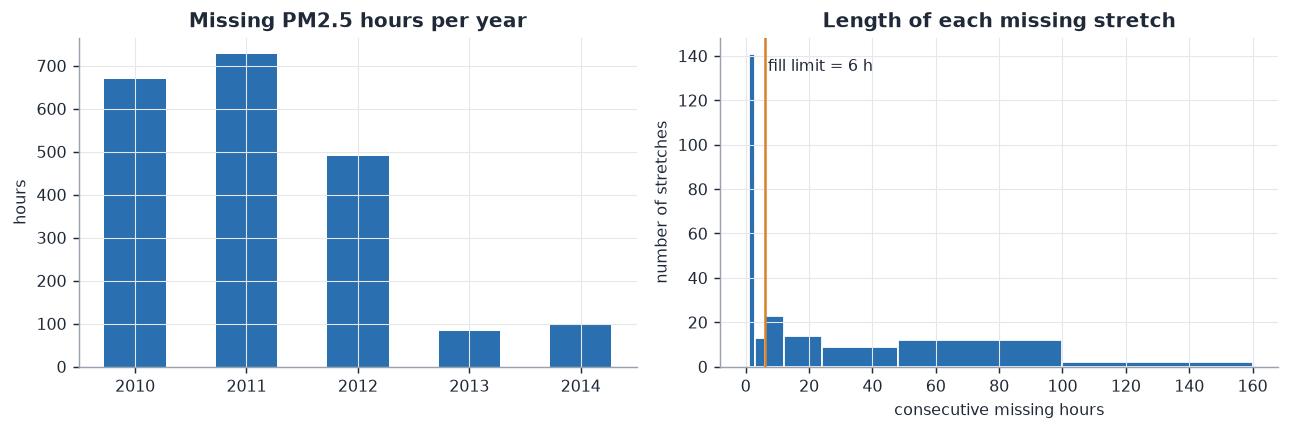

A2_imputation_simulation


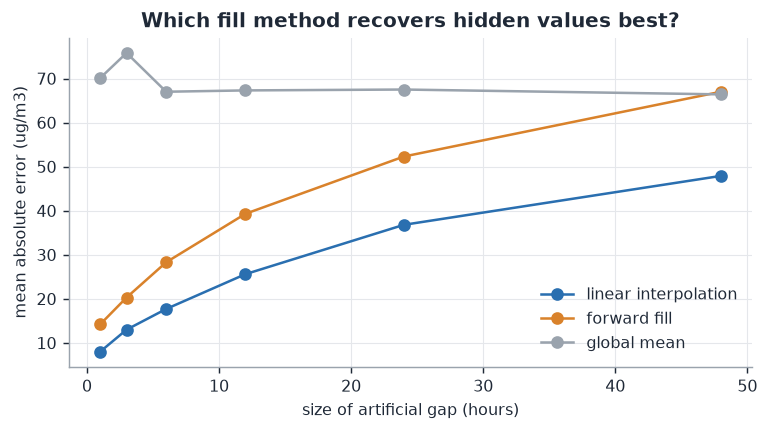

A3_distributions


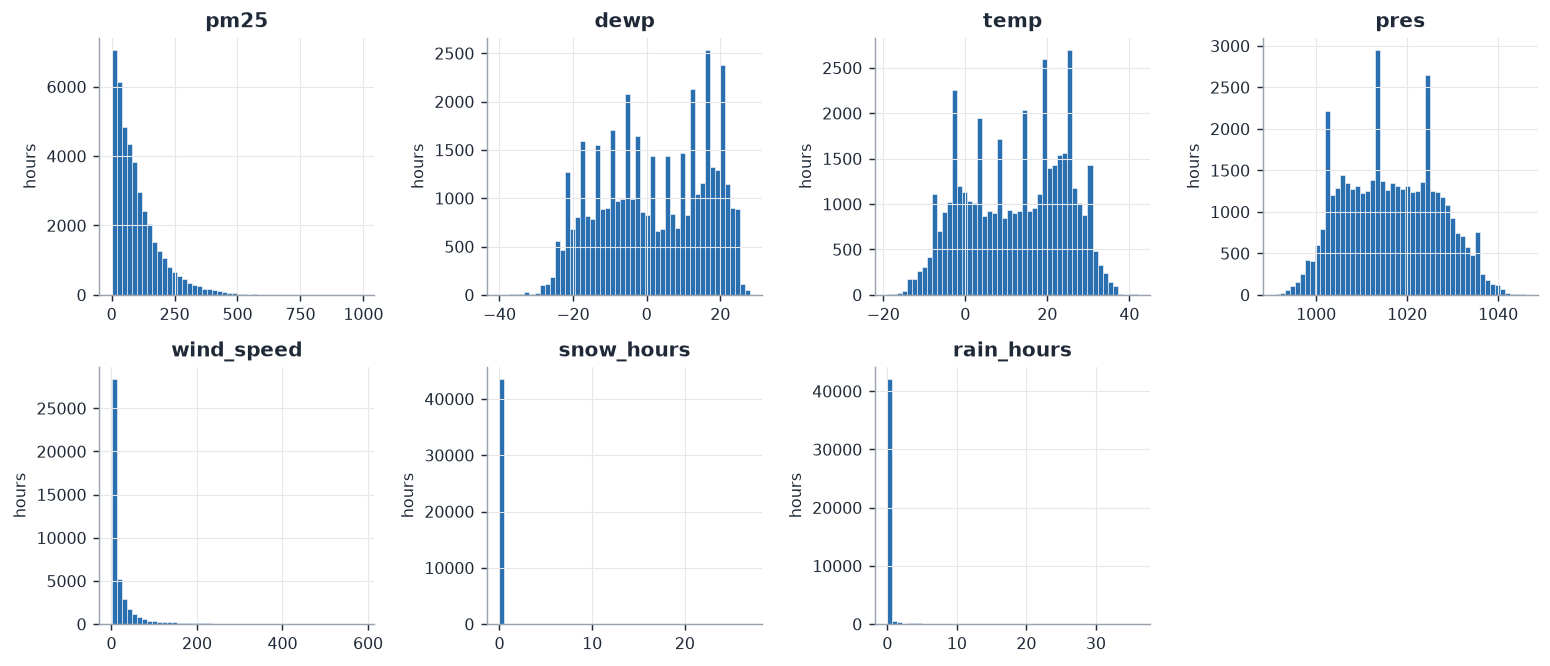

A4_pm25_outliers_log


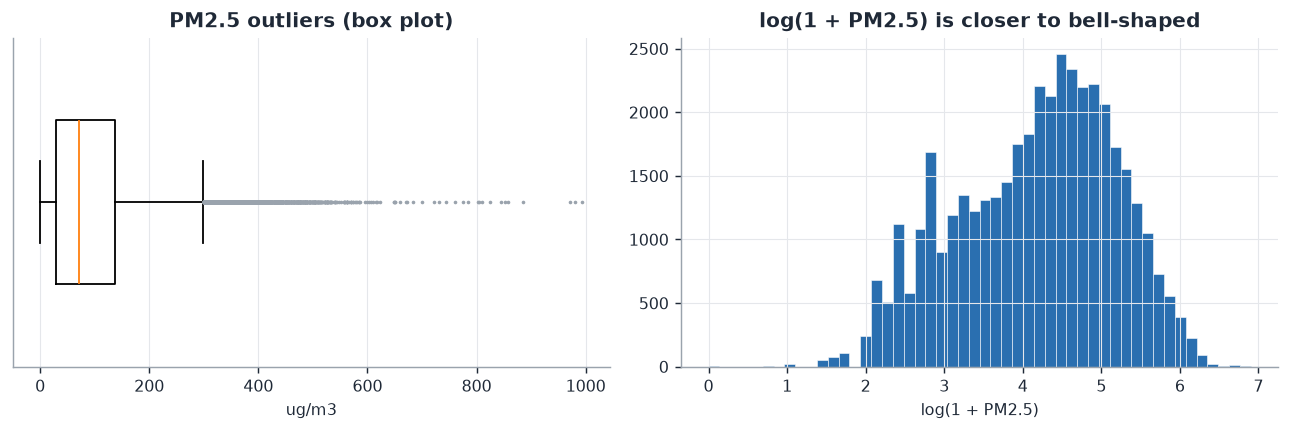

In [4]:
for name in ["A1_missing_values", "A2_imputation_simulation", "A3_distributions", "A4_pm25_outliers_log"]:
    print(name)
    display(Image(filename=str(FIG_DIR / f"{name}.png")))

## 4. Analytical questions

Each question below is answered with a saved visualization and values computed from the cleaned hourly series. Associations are descriptive and should not be interpreted as causal effects.

### Q1. Is there a long-term trend in PM2.5?

The code displays the saved trend figure and reads the yearly means, hours above 150, slope, p-value, and R-squared from the EDA results. The daily series and 30-/365-day moving averages show short-term variability and the longer-term baseline.

**Interpretation of the output:** yearly means are 104.1, 99.1, 90.5, 101.7, and 97.6 ug/m3 (2010–2014). The fitted daily-mean slope is -1.18 ug/m3 per year, but p = 0.355 and R-squared = 0.0005. Since the p-value exceeds 0.05 and the fit explains almost none of the variation, the data do not provide evidence of a linear long-term trend. The dips and rebounds in individual years are variability, not a sustained improvement.

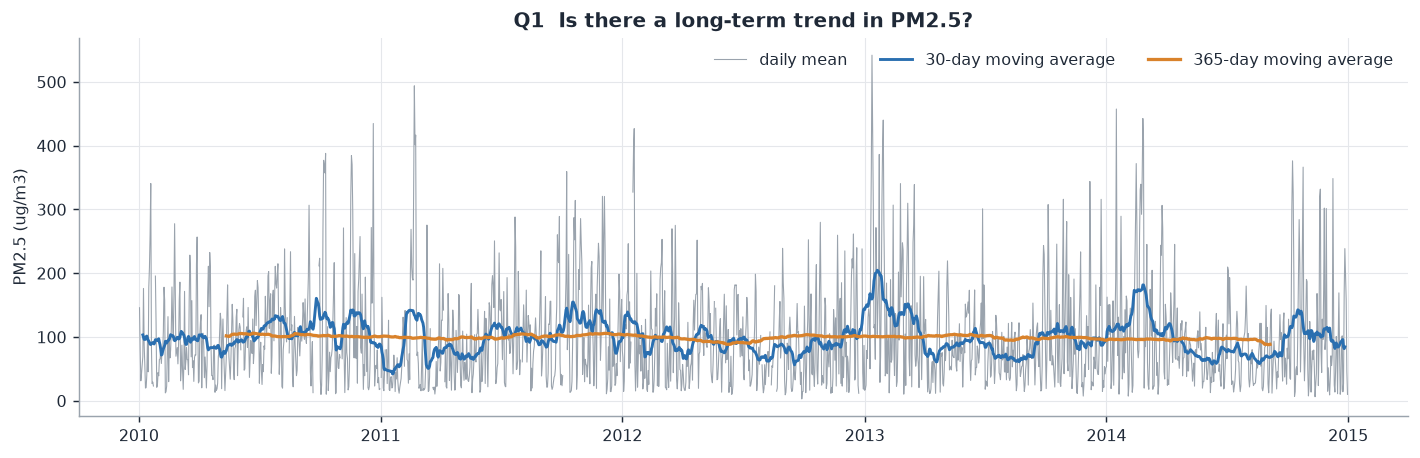

Yearly means: {'2010': 104.1, '2011': 99.1, '2012': 90.5, '2013': 101.7, '2014': 97.6}
Estimated slope: -1.18 ug/m3/year; p=0.355; R2=0.0005.
Interpretation: the fitted trend is not statistically distinguishable from zero at the 5% level. The yearly variation does not support a clear monotonic improvement or worsening.


In [5]:
display(Image(filename=str(FIG_DIR / "Q1_trend.png")))
q1 = findings["Q1"]
print("Yearly means:", q1["yearly_mean"])
print(f"Estimated slope: {q1['slope_ug_per_year']:.2f} ug/m3/year; p={q1['p_value']:.3f}; R2={q1['r2']:.4f}.")
if q1["p_value"] < 0.05:
    print("Interpretation: the fitted daily-mean trend is statistically distinguishable from zero at the 5% level; quantify the direction using the slope.")
else:
    print("Interpretation: the fitted trend is not statistically distinguishable from zero at the 5% level. The yearly variation does not support a clear monotonic improvement or worsening.")

### Q2. Is there a seasonal pattern across months?

The code groups the EDA-cleaned PM2.5 series by calendar month, plots the 12 means, calculates winter (December–February) and summer (June–August) averages, and reports the highest and lowest month.

**Interpretation of the output:** February has the highest monthly mean (126.1 ug/m3), while August has the lowest (80.0). The winter mean is 112.9 versus 90.3 in summer, about 25% higher. October is also elevated (120.3), so the pattern is seasonal but not simply a single winter peak. These descriptive comparisons do not identify the causes of the differences.

C:\Program Files\KMSpico\temp\ipykernel_29900\1196240030.py:27: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


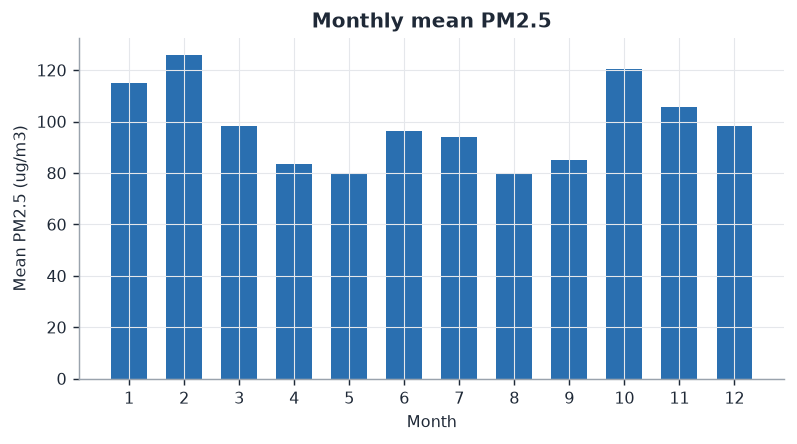

Highest monthly mean: Feb (126.1); lowest: Aug (80.0) ug/m3.
Winter mean: 112.9; summer mean: 90.3 ug/m3.
Interpretation: compare the seasonal means and monthly extremes; describe the observed seasonality without attributing it to a cause this analysis did not test.


In [6]:
monthly_means = clean["pm25"].groupby(clean.index.month).mean()
fig, ax = plt.subplots(figsize=(7, 3.4))
ax.bar(monthly_means.index, monthly_means.values, color="#2a6fb0", width=0.65)
ax.set_xticks(range(1, 13))
ax.set_xlabel("Month")
ax.set_ylabel("Mean PM2.5 (ug/m3)")
ax.set_title("Monthly mean PM2.5")
save_fig("Q2_seasonality")
display(Image(filename=str(FIG_DIR / "Q2_seasonality.png")))
q2 = findings["Q2"]
month_names = {1: "Jan", 2: "Feb", 3: "Mar", 4: "Apr", 5: "May", 6: "Jun", 7: "Jul", 8: "Aug", 9: "Sep", 10: "Oct", 11: "Nov", 12: "Dec"}
highest = max(q2["monthly_mean"], key=q2["monthly_mean"].get)
lowest = min(q2["monthly_mean"], key=q2["monthly_mean"].get)
print(f"Highest monthly mean: {month_names[int(highest)]} ({q2['monthly_mean'][highest]:.1f}); lowest: {month_names[int(lowest)]} ({q2['monthly_mean'][lowest]:.1f}) ug/m3.")
print(f"Winter mean: {q2['winter_djf_mean']:.1f}; summer mean: {q2['summer_jja_mean']:.1f} ug/m3.")
print("Interpretation: compare the seasonal means and monthly extremes; describe the observed seasonality without attributing it to a cause this analysis did not test.")

### Q3. Does PM2.5 vary by hour of the day?

The code displays the saved hourly profiles for winter and summer and reports the maximum and minimum mean PM2.5 hour for each season.

**Interpretation of the output:** winter PM2.5 peaks at 01:00 (143.1 ug/m3) and reaches its minimum at 14:00 (90.8). Summer peaks at 07:00 (98.4) and is lowest at 16:00 (80.2). The afternoon minima are lower than the winter nighttime peak, but this plot alone cannot establish a physical mechanism.

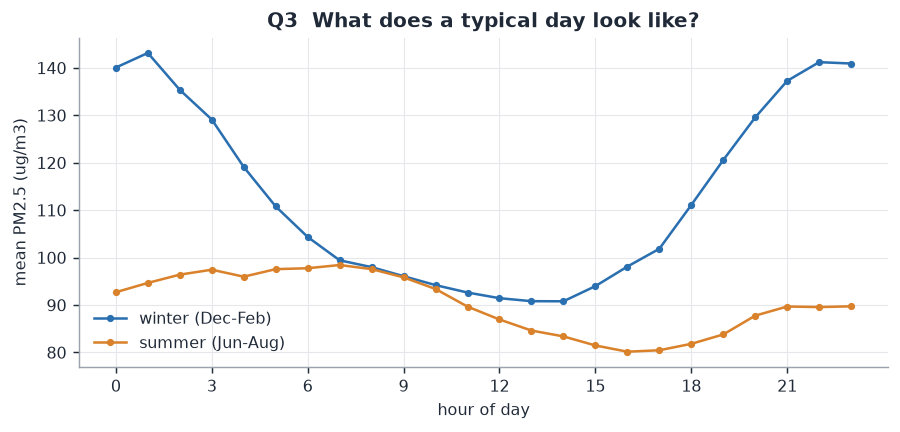

Winter: peak 143.1 at 01:00; low 90.8 at 14:00.
Summer: peak 98.4 at 07:00; low 80.2 at 16:00.
Interpretation: the peak/trough timing and seasonal difference show the observed daily cycle; the plot alone cannot identify its mechanism.


In [7]:
display(Image(filename=str(FIG_DIR / "Q3_daily_cycle.png")))
q3 = findings["Q3"]
print(f"Winter: peak {q3['winter_peak']:.1f} at {q3['winter_peak_hour']:02d}:00; low {q3['winter_low']:.1f} at {q3['winter_low_hour']:02d}:00.")
print(f"Summer: peak {q3['summer_peak']:.1f} at {q3['summer_peak_hour']:02d}:00; low {q3['summer_low']:.1f} at {q3['summer_low_hour']:02d}:00.")
print("Interpretation: the peak/trough timing and seasonal difference show the observed daily cycle; the plot alone cannot identify its mechanism.")

### Q4. Which measured weather variables are associated with PM2.5?

The code displays a Pearson correlation heatmap and PM2.5 box plots by wind direction, then prints Pearson and Spearman correlations with PM2.5 and category medians. Pearson measures linear association; Spearman measures rank/monotonic association. Neither establishes causation.

**Interpretation of the output:** the largest listed linear association is negative for wind speed (Pearson -0.25); dew point is weakly positive (+0.17). Wind speed and dew point have stronger Spearman correlations (-0.36 and +0.30), suggesting the relationships are not fully captured by a straight-line association. Median PM2.5 is lowest for NW winds (31) and highest for calm/variable winds (98). Weather variables can co-vary, so these pairwise relationships are descriptive rather than causal.

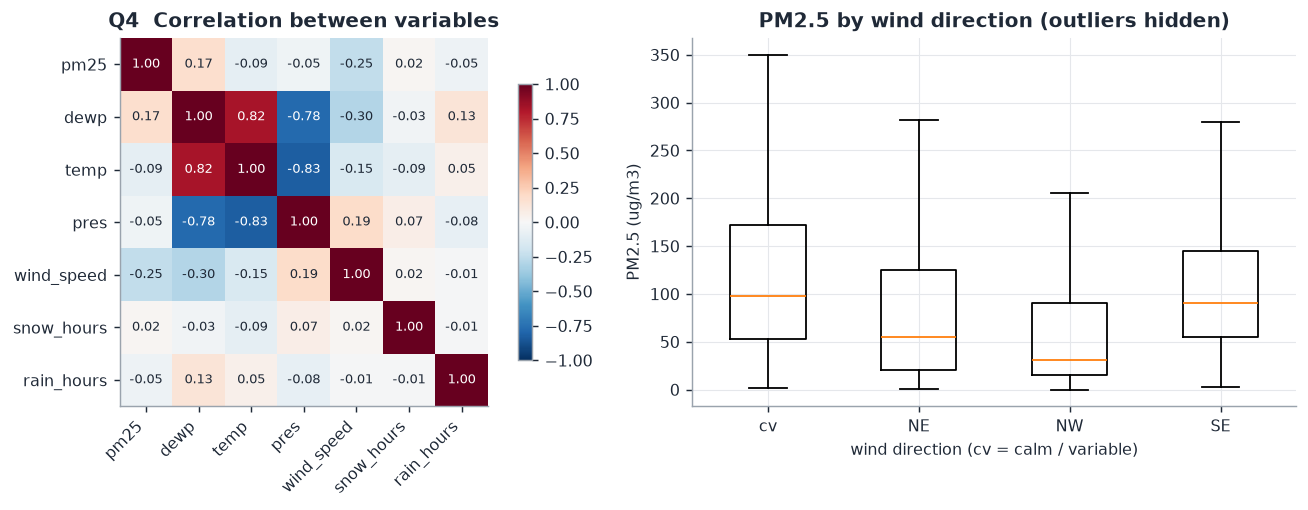

Pearson correlations with PM2.5: {'dewp': 0.17, 'temp': -0.09, 'pres': -0.05, 'wind_speed': -0.25, 'snow_hours': 0.02, 'rain_hours': -0.05}
Spearman correlations with PM2.5: {'pm25': 1.0, 'dewp': 0.3, 'temp': 0.01, 'pres': -0.14, 'wind_speed': -0.36, 'snow_hours': 0.05, 'rain_hours': -0.0}
Median PM2.5 by wind direction: {'NE': 55.0, 'NW': 31.0, 'SE': 91.0, 'cv': 98.0}
Interpretation: compare Pearson and Spearman to identify relationships that may be monotonic but not linear. Wind-direction medians show category differences; correlated weather variables may confound these associations.


In [8]:
display(Image(filename=str(FIG_DIR / "Q4_weather_correlation.png")))
q4 = findings["Q4"]
associations = {k: v for k, v in q4["pearson_with_pm25"].items() if k != "pm25"}
print("Pearson correlations with PM2.5:", associations)
print("Spearman correlations with PM2.5:", q4["spearman_with_pm25"])
print("Median PM2.5 by wind direction:", q4["median_by_wind_dir"])
print("Interpretation: compare Pearson and Spearman to identify relationships that may be monotonic but not linear. Wind-direction medians show category differences; correlated weather variables may confound these associations.")

### Q5. How strongly do lagged PM2.5 features relate to current concentration?

The code displays the saved autocorrelation plot and prints selected correlations between PM2.5 and its past values at lags from one to 72 hours. High autocorrelation means nearby readings tend to move together; it is not itself an out-of-sample forecast score.

**Interpretation of the output:** autocorrelation is 0.965 at one hour, 0.745 at six hours, 0.398 at 24 hours, and 0.073 at 72 hours. This is strong short-term persistence that declines with time. It supports testing lagged PM2.5 features, while the much smaller 72-hour value indicates weaker direct association at longer lags.

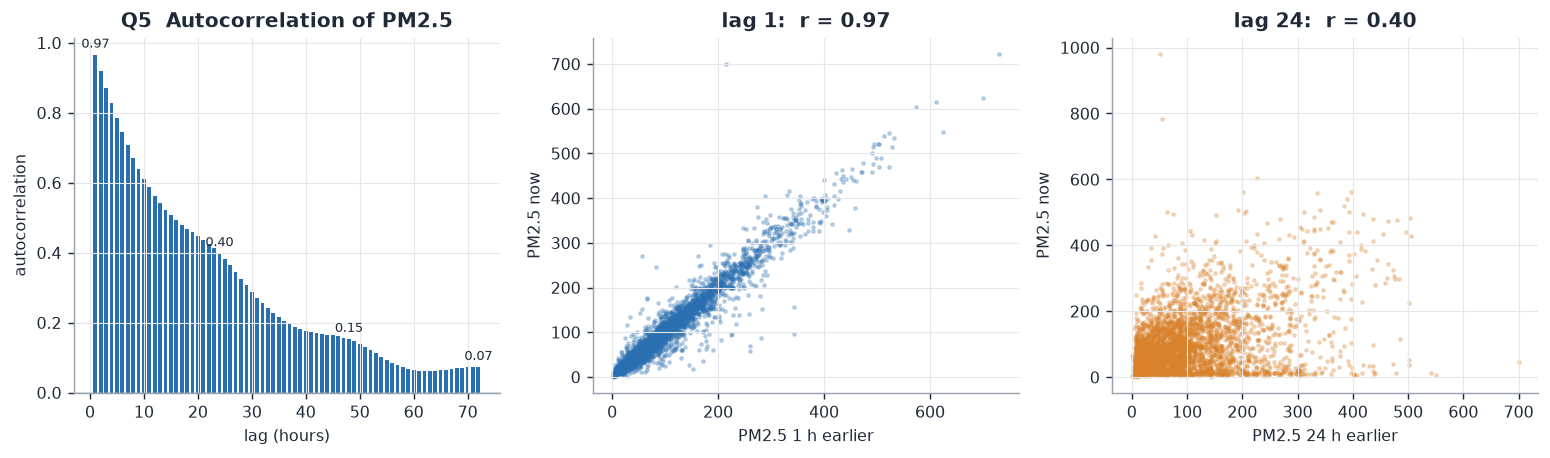

Autocorrelation: {'acf_lag1': 0.965, 'acf_lag2': 0.919, 'acf_lag3': 0.872, 'acf_lag6': 0.745, 'acf_lag12': 0.563, 'acf_lag24': 0.398, 'acf_lag48': 0.153, 'acf_lag72': 0.073}
Interpretation: lag-1 autocorrelation is 0.965, falling to 0.398 at 24 hours and 0.073 at 72 hours. This indicates strong short-term persistence that decays with lag; autocorrelation is not itself a forecast score.


In [9]:
display(Image(filename=str(FIG_DIR / "Q5_lag_effects.png")))
q5 = findings["Q5"]
print("Autocorrelation:", {k: v for k, v in q5.items()})
print(f"Interpretation: lag-1 autocorrelation is {q5['acf_lag1']:.3f}, falling to {q5['acf_lag24']:.3f} at 24 hours and {q5['acf_lag72']:.3f} at 72 hours. This indicates strong short-term persistence that decays with lag; autocorrelation is not itself a forecast score.")

### Q6. How do moving averages smooth PM2.5, and how are they related to the six-hour-ahead target?

The code displays hourly readings alongside trailing six- and 24-hour means, then reports each rolling-window mean's correlation with PM2.5 six hours later. A trailing mean uses the current and preceding readings only; wider windows smooth more short-term variation.

**Interpretation of the output:** the one-hour value has the largest correlation with the six-hour-ahead target (0.745). The correlation declines as the window grows: 0.585 for 24 hours and 0.233 for 168 hours. Wider windows reveal the background level more smoothly but respond less closely to this short forecast horizon. These are associations computed on the series, not a substitute for held-out model evaluation.

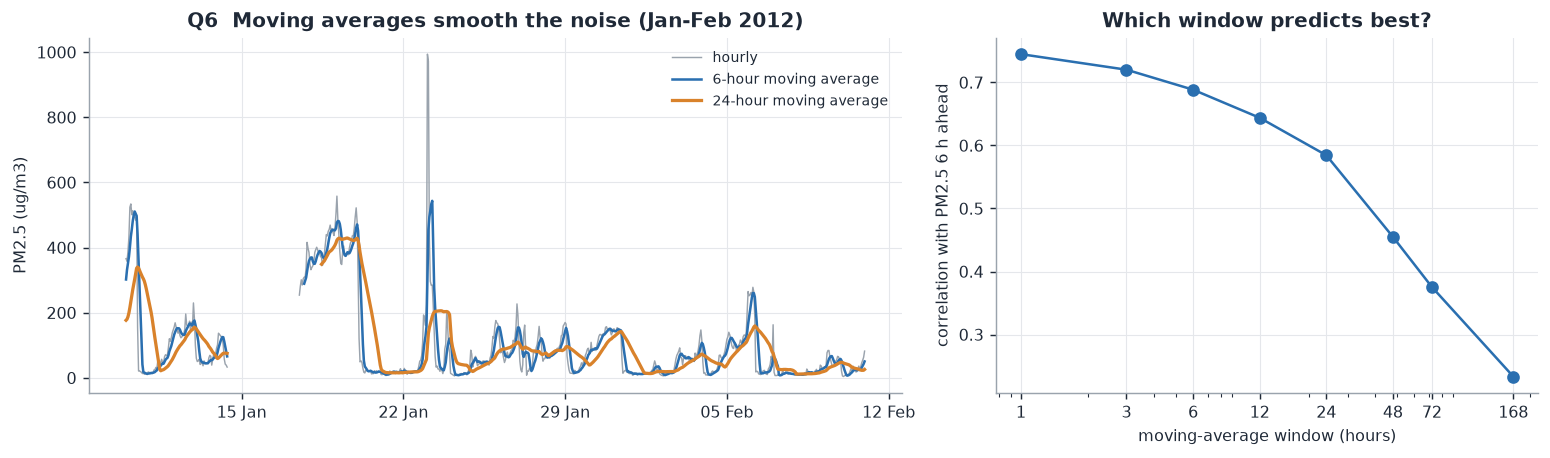

Moving-average correlation with the six-hour-ahead target: {'1': 0.7449, '3': 0.7202, '6': 0.6885, '12': 0.6439, '24': 0.5845, '48': 0.455, '72': 0.3755, '168': 0.2334}
Interpretation: the 1-hour value has correlation 0.745, compared with 0.585 for 24 hours and 0.233 for 168 hours. Longer averages smooth noise but show weaker association with this short-horizon target; the model experiments test predictive value out of sample.


In [10]:
display(Image(filename=str(FIG_DIR / "Q6_moving_averages.png")))
q6 = findings["Q6"]["corr_next_hour_vs_ma_window"]
print("Moving-average correlation with the six-hour-ahead target:", q6)
print(f"Interpretation: the 1-hour value has correlation {q6['1']:.3f}, compared with {q6['24']:.3f} for 24 hours and {q6['168']:.3f} for 168 hours. Longer averages smooth noise but show weaker association with this short-horizon target; the model experiments test predictive value out of sample.")

### Q7. Does wind speed have a delayed association with PM2.5 (lagged external variable)?

The code displays cross-correlations between PM2.5 and wind speed shifted by 0–48 hours and groups PM2.5 means into wind-speed bins. The dataset's wind-speed field is cumulative, so these are associations with the recorded measure, not a causal intervention.

**Interpretation of the output:** the strongest negative correlation occurs at lag 0 (-0.248) and weakens at 6, 12, and 24 hours (-0.227, -0.198, and -0.148). There is no later-lag peak in the reported values, so the results do not indicate a distinct delayed association. Mean PM2.5 falls from 137.3 in the lowest wind bin (at most 1) to 41.1 above 50; this pattern is descriptive and could reflect other covarying conditions.

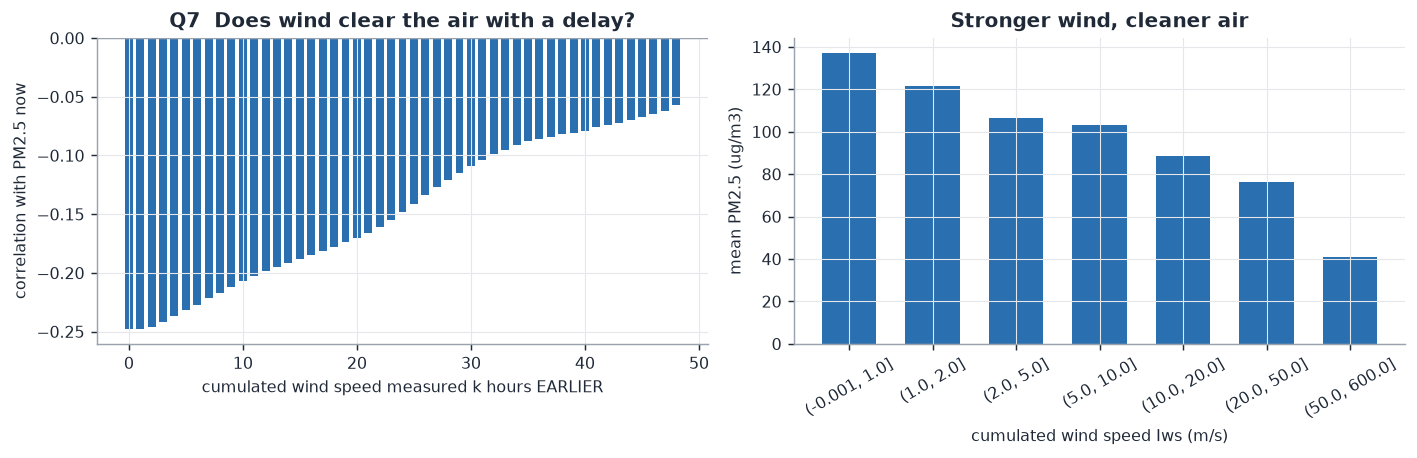

Wind/PM2.5 correlation: lag 0=-0.248, 6 h=-0.227, 12 h=-0.198, 24 h=-0.148.
Most negative association in the examined lags: lag 0 h (-0.248).
Interpretation: check whether the association strengthens at a later lag or fades from lag zero. A fading pattern is consistent with an immediate association plus persistence, not evidence of a delayed causal effect.


In [11]:
display(Image(filename=str(FIG_DIR / "Q7_wind_lag.png")))
q7 = findings["Q7"]
print(f"Wind/PM2.5 correlation: lag 0={q7['corr_wind_lag0']:.3f}, 6 h={q7['corr_wind_lag6']:.3f}, 12 h={q7['corr_wind_lag12']:.3f}, 24 h={q7['corr_wind_lag24']:.3f}.")
print(f"Most negative association in the examined lags: lag {q7['most_negative_lag']} h ({q7['most_negative_value']:.3f}).")
print("Interpretation: check whether the association strengthens at a later lag or fades from lag zero. A fading pattern is consistent with an immediate association plus persistence, not evidence of a delayed causal effect.")

## 5. Forecast features and leakage-safe evaluation

The code prepares PM2.5 inputs with forward fill limited to six hours (so no later readings are used), builds 32 current, lag, moving-average, weather, and calendar features, and sets the label to observed PM2.5 six hours ahead. It drops rows with incomplete feature history or a missing target. The split is chronological—train through 2012, validate in 2013, test in 2014—and the six-hour embargo prevents a label from crossing a split boundary.

**Interpretation of the output:** 38,753 usable rows remain: 21,943 train, 8,558 validation, and 8,246 test examples. The printed boundary timestamps and assertions check that the time ordering and forecast horizon are respected. This deliberately excludes some hours; the smaller sample is preferable to using imputed future labels or leaking targets across partitions.

In [12]:
forecast_observations = raw.asfreq("h")
forecast_features = forecast_observations.copy()
forecast_features["pm25"] = forecast_observations["pm25"].ffill(limit=MAX_INTERP_GAP)
X, y = build_features(forecast_features, target_values=forecast_observations["pm25"])
(X_train, y_train), (X_val, y_val), (X_test, y_test) = chronological_split(X, y)
print(f"Features: {X.shape[1]} | usable examples: {len(X):,}")
print(f"Train: {len(X_train):,} | validation: {len(X_val):,} | test: {len(X_test):,}")
print("Train ends:", X_train.index.max(), "| validation:", X_val.index.min(), "to", X_val.index.max(), "| test begins:", X_test.index.min())
print("Lag features:", [c for c in X if "_lag" in c])
print("Moving-average features:", [c for c in X if "_ma" in c])
assert X_train.index.max() + pd.Timedelta(hours=HORIZON) < X_val.index.min()
assert X_val.index.max() + pd.Timedelta(hours=HORIZON) < X_test.index.min()
assert not X.isna().any().any() and not y.isna().any()

Features: 32 | usable examples: 38,753


Train: 21,943 | validation: 8,558 | test: 8,246
Train ends: 2012-12-31 17:00:00 | validation: 2013-01-01 00:00:00 to 2013-12-29 11:00:00 | test begins: 2014-01-02 10:00:00
Lag features: ['pm25_lag1', 'pm25_lag2', 'pm25_lag3', 'pm25_lag6', 'pm25_lag12', 'pm25_lag24', 'temp_lag24']
Moving-average features: ['pm25_ma3', 'pm25_ma6', 'pm25_ma12', 'pm25_ma24', 'pm25_ma72', 'wind_speed_ma6']


## 6. Tuned model experiments and final test

The code runs `scripts/02_train_models.py`, which compares a persistence baseline with five tuned model/feature configurations. Grid/randomized search uses four chronological cross-validation folds within the training period, with a six-hour gap; candidates are selected by validation RMSE on 2013. The selected configuration is refit on training plus validation data and evaluated on observed 2014 targets. It also writes the experiment/tuning tables, final model metadata, and forecast figures.

In [13]:
training_results = runpy.run_path("scripts/02_train_models.py")
experiment_table = pd.read_csv("outputs/tables/experiment_table.csv")
display(experiment_table.sort_values("val_RMSE").reset_index(drop=True))
metadata = json.loads(Path("models/model_metadata.json").read_text(encoding="utf-8"))
print("Selected model:", metadata["model_name"])
print("Best parameters:", metadata["best_params"])
print("Forecast horizon:", metadata["horizon_hours"], "hours")
print("Final 2014 test metrics after refit:", metadata["test_metrics_after_refit"])
print("Persistence baseline test metrics:", metadata["persistence_baseline_test"])
save_table(experiment_table, "experiment_table", index=False)

rows  train=21943  validation=8558  test=8246
features: 32
PM2.5 feature gaps: causal forward fill, at most 6 hours; target labels use observed PM2.5 only


Exp1_Ridge_all_features                    cv= 58.41 val_RMSE= 62.04 test_RMSE= 55.34  (10s)


Exp2_RandomForest_no_lags                  cv= 59.75 val_RMSE= 61.62 test_RMSE= 54.28  (55s)


Exp3_RandomForest_all_features             cv= 59.19 val_RMSE= 61.45 test_RMSE= 55.09  (226s)


Exp4_HistGradientBoosting_all_features     cv= 58.61 val_RMSE= 61.63 test_RMSE= 55.38  (69s)


...

Final model on 2014 test: {'MAE': 34.817, 'RMSE': 53.958, 'R2': 0.671}



MAE by pollution level:
 level
0-35       28.9
35-75      26.5
75-150     27.5
150-250    45.3
>250       90.0


,experiment,model,n_features,best_hyperparameters,cv_RMSE,val_MAE,val_RMSE,val_R2,test_MAE,test_RMSE,test_R2,fit_seconds
0,Exp3_RandomForest_all_features,"Random Forest, lag + moving-average features",32,"{""n_estimators"": 100, ""min_samples_leaf"": 20, ...",59.19,38.42,61.45,0.6110,35.35,55.09,0.6574,225.9
1,Exp2_RandomForest_no_lags,Random Forest WITHOUT lag/moving-average featu...,16,"{""n_estimators"": 200, ""min_samples_leaf"": 20, ...",59.75,38.41,61.62,0.6089,35.46,54.28,0.6674,55.5
2,Exp4_HistGradientBoosting_all_features,"Histogram gradient boosting, lag + moving-aver...",32,"{""min_samples_leaf"": 20, ""max_iter"": 600, ""max...",58.61,38.73,61.63,0.6087,35.71,55.38,0.6537,69.3
3,Exp1_Ridge_all_features,"Ridge regression, lag + moving-average features",32,"{""m__alpha"": 100}",58.41,40.25,62.04,0.6035,36.99,55.34,0.6544,10.1
4,Exp5_HistGradientBoosting_pm25_history_only,Histogram gradient boosting using ONLY PM2.5 h...,19,"{""min_samples_leaf"": 20, ""max_iter"": 600, ""max...",61.10,40.33,63.43,0.5855,36.95,57.13,0.6316,78.6
5,Exp0_Persistence_baseline,PM2.5 in 6 h = PM2.5 now,1,none,NaN,42.77,69.89,0.4968,38.66,61.38,0.5747,0.0


Selected model: Exp3_RandomForest_all_features
Best parameters: {'n_estimators': 100, 'min_samples_leaf': 20, 'max_features': 0.6, 'max_depth': 20}
Forecast horizon: 6 hours
Final 2014 test metrics after refit: {'MAE': 34.816762930300634, 'RMSE': 53.958402663740266, 'R2': 0.6713533027826062}
Persistence baseline test metrics: {'MAE': 38.66420082464225, 'RMSE': 61.37924695947838, 'R2': 0.5747403136614017}


WindowsPath('outputs/tables/experiment_table.csv')

### Model interpretation and saved experiment evidence

**What the model output shows:** Exp3 (Random Forest with all 32 features) has the lowest validation RMSE among the tuned experiments (61.45), so it is selected before considering test performance. After refitting on training plus validation, its 2014 test RMSE is 53.96, MAE is 34.82, and R-squared is 0.671. The persistence baseline's test RMSE is 61.38 (R-squared 0.575), so the selected model improves on carrying the current reading forward six hours.

In the experiment table, the Random Forest without lag/moving-average features has slightly lower test RMSE than the all-feature Random Forest (54.28 versus 55.09); adding these features did not improve this comparison. The differences among the main tuned models are small, so avoid claiming a definitive model winner from test scores. The history-only versus weather-inclusive HistGradientBoosting comparison is consistent with weather adding useful signal (57.13 versus 55.38 RMSE), but it is not a causal estimate. The error-by-pollution-level output shows MAE rising to 90.0 above 250 ug/m3, highlighting weaker performance during severe episodes.

The next cell shows the test-RMSE comparison, the selected model's predicted-versus-actual plot, and feature importance. The selected Random Forest uses impurity-based importance here: PM2.5 at the forecast origin is dominant (about 0.526), followed by the three-hour mean (about 0.148). Importance summarizes how the fitted trees used predictors; it is not a causal effect or a percentage of forecast accuracy.

M1_experiment_comparison


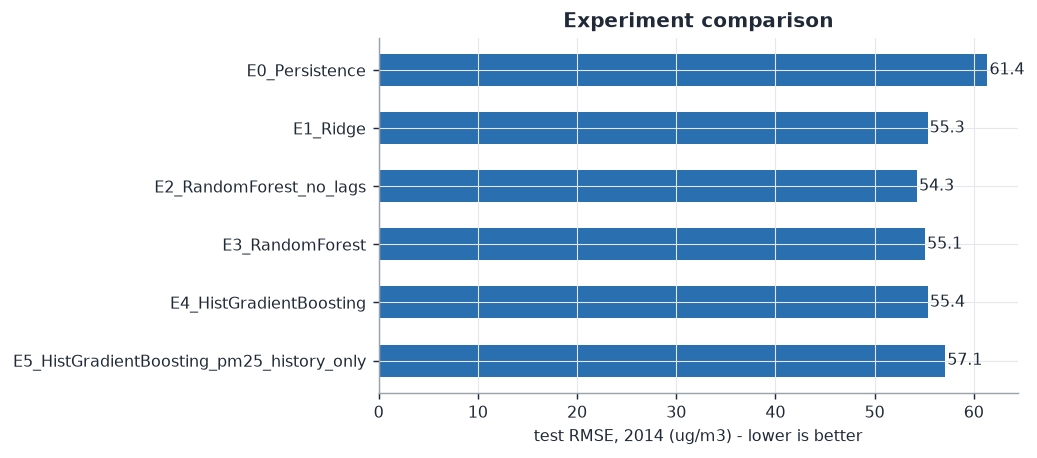

M2_predicted_vs_actual


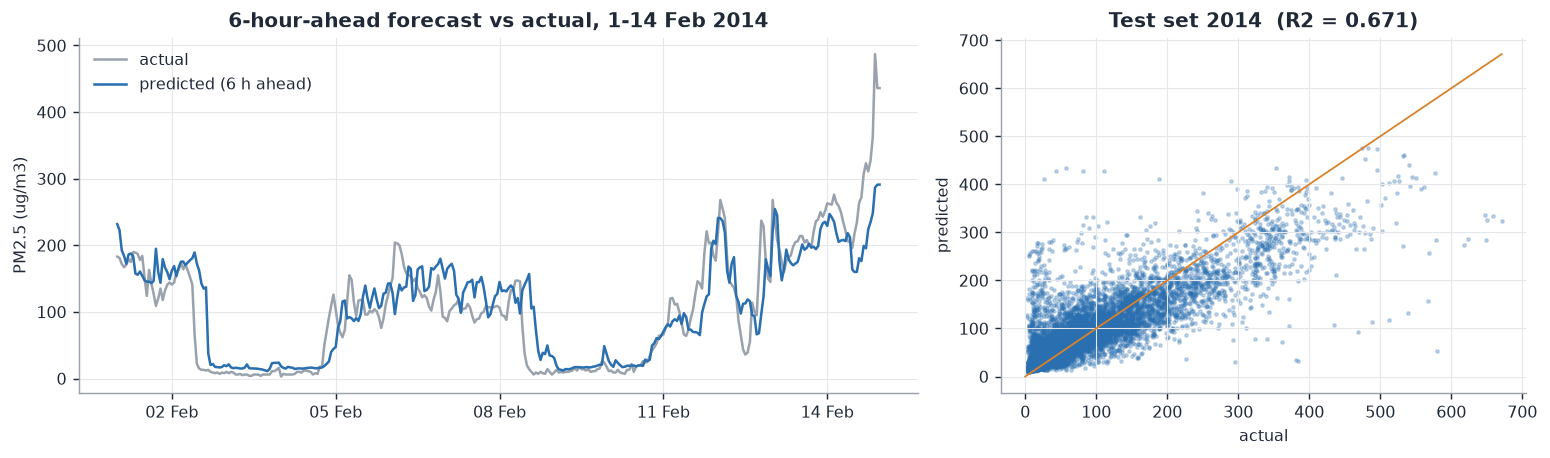

M3_feature_importance


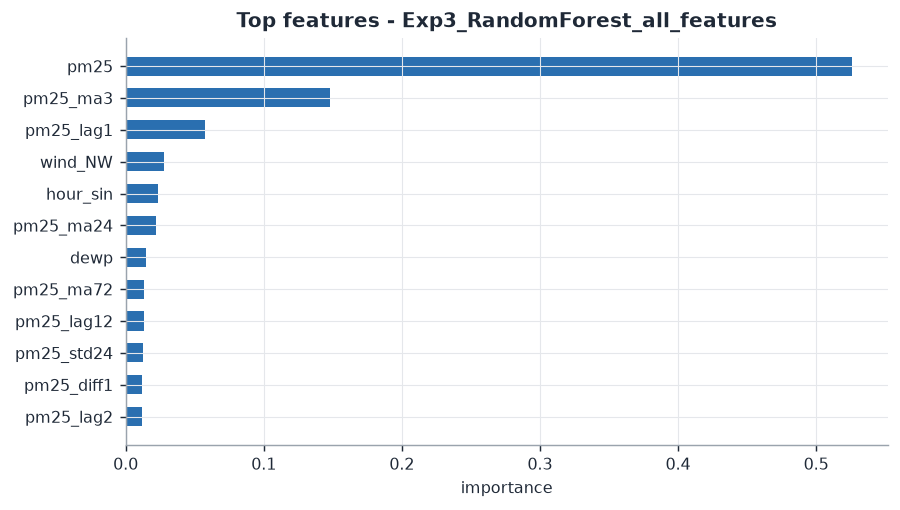

,importance
pm25,0.525673
pm25_ma3,0.147828
pm25_lag1,0.057206
wind_NW,0.027729
hour_sin,0.023331
pm25_ma24,0.022194
dewp,0.014410
pm25_ma72,0.013570
pm25_lag12,0.013322
pm25_std24,0.012309


In [14]:
for name in ["M1_experiment_comparison", "M2_predicted_vs_actual", "M3_feature_importance"]:
    print(name)
    display(Image(filename=str(FIG_DIR / f"{name}.png")))
display(pd.read_csv("outputs/tables/feature_importance.csv", index_col=0).head(15))

## 7. Task 1 conclusions

This analysis covers five years of hourly Beijing PM2.5 and weather data. PM2.5 has a right-skewed distribution and 4.72% missing values; short internal gaps are interpolated for EDA, while long outages remain missing. The seven questions show no statistically significant long-term trend, seasonal and daily variation, strong short-term PM2.5 persistence, decreasing association between longer rolling means and the six-hour target, and an immediate rather than delayed wind-speed association. These associations are descriptive, not causal.

For forecasting, the selected Random Forest predicts observed PM2.5 six hours ahead using causal inputs and a chronological, embargoed split. Its final 2014 RMSE is 53.96 versus 61.38 for persistence. Errors are substantially larger during severe pollution, and the all-feature model did not beat the no-lag Random Forest on the experiment-table test comparison. Figures and detailed numerical outputs are saved under `outputs/`; the final fitted pipeline and its evaluation metadata are under `models/`.